# 기초데이터과학 (01분반)

## 10-1. 데이터 시각화 2 (관계와 다변수)

### Acknowledgement

#### 이 자료는 다음 서적 및 자료의 내용을 바탕으로 작성되었음
- 파이썬 라이브러리를 활용한 데이터 분석. 한빛미디어
- 쉽게 배우는 파이썬 데이터 분석. 이지스 퍼블리싱
- Do it! 데이터 분석을 위한 판다스 입문. 전면 개정판. 이지스 퍼블리싱
- Seaborn을 사용한 데이터 분포 시각화 (데이터 사이언스 스쿨: datascienceschool.net)

### 지난 시간 복습
- 그래프는 **무엇을 보고 싶은가**에 따라 적절한 유형을 선택함

| 보고 싶은 것 | 주로 쓰는 그래프 |
|---|---|
| 추세 | 선 그래프 | 
| 분포 | 히스토그램, 밀도 그래프 | 
| 그룹 간 비교 | 상자 그림, 바이올린, 막대 그래프 | 
| **관계** | 산점도, 회귀선 | 
| **여러 변수** | 색상 구분, 나눠 그리기, heatmap | 

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

penguins = sns.load_dataset('penguins')
print(penguins.head())

  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       3450.0  Female  


### 관계 보기 - 두 변수가 함께 변하는가

#### 산점도 (Scatter plot)
- 두 숫자형 변수를 x축과 y축에 놓고, 데이터 하나를 점 하나로 표현
- 두 변수 사이의 관계나 패턴을 쉽게 파악할 수 있음

##### 산점도를 활용하는 경우
- 두 변수 간의 관계를 확인하는 경우
  - 한 변수가 커질 때 다른 변수도 커지는가 (양의 관계), 작아지는가 (음의 관계), 상관없는가
  - 키와 몸무게, 공부 시간과 시험 점수, 광고비와 매출액
- 데이터가 몇 개의 무리로 나뉘는지 확인하는 경우
- 일반적인 패턴에서 벗어난 이상치를 찾는 경우

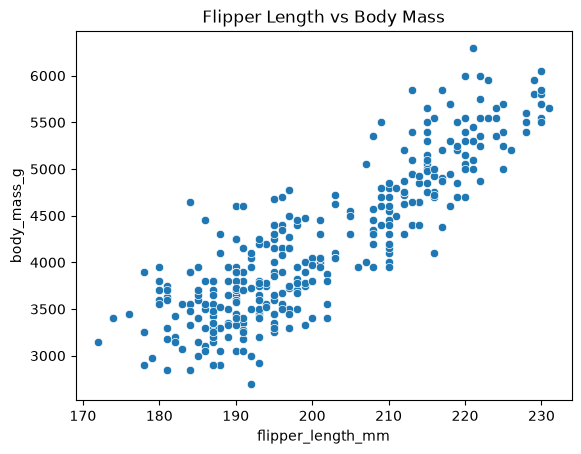

In [2]:
sns.scatterplot(data=penguins, x='flipper_length_mm', y='body_mass_g')

plt.title('Flipper Length vs Body Mass')
plt.show()

- 지느러미가 길수록 체중이 무거운 **양의 관계**가 뚜렷함

#### 회귀선이 포함된 산점도
- `regplot( )` : 산점도 위에 점들의 경향을 나타내는 직선(회귀선)을 함께 그림
  - 직선이 오른쪽 위로 올라가면 양의 관계, 오른쪽 아래로 내려가면 음의 관계
  - 직선 주변의 옅은 띠는 직선의 위치에 대한 불확실성을 나타냄

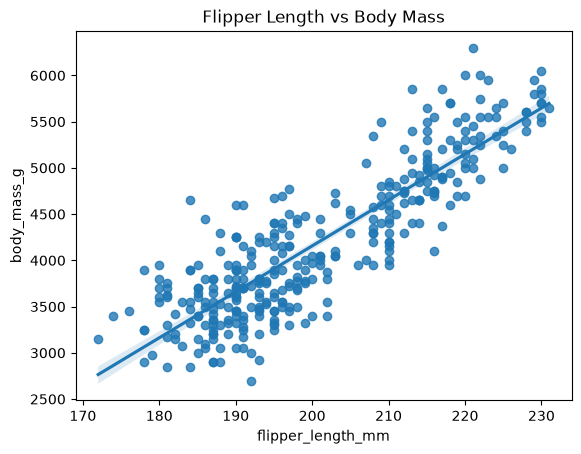

In [3]:
sns.regplot(data=penguins, x='flipper_length_mm', y='body_mass_g')

plt.title('Flipper Length vs Body Mass')
plt.show()

#### 조인트 그래프
- `jointplot( )` : 산점도의 위쪽과 오른쪽에 각 변수의 분포를 함께 그림
- 관계와 각 변수의 분포를 한 번에 볼 수 있음
- 제목은 `plt.suptitle( )` 로 지정함. 그래프가 여러 칸으로 이루어져 있기 때문

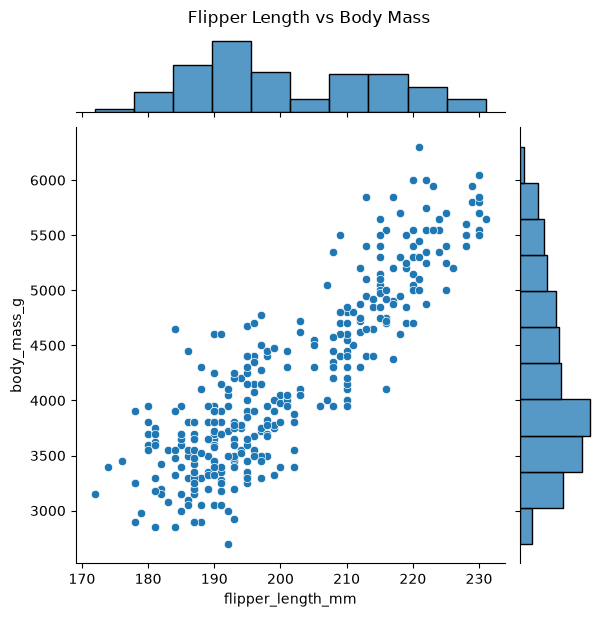

In [4]:
sns.jointplot(data=penguins, x='flipper_length_mm', y='body_mass_g')

plt.suptitle('Flipper Length vs Body Mass', y=1.02)
plt.show()

### 아래 셀을 실행하기 전에 생각해 볼 것

- 이번에는 **부리 길이**(`bill_length_mm`)와 **부리 깊이**(`bill_depth_mm`)의 관계를 봄
- 아래 셀은 펭귄 전체를 대상으로 회귀선을 그림
- 그 다음 셀은 같은 데이터를 **종별로 색을 나누어** 회귀선을 그림
- 두 그래프의 회귀선 방향이 같을지 다를지 예측해 볼 것

> 나의 예측:

In [ ]:
sns.regplot(data=penguins, x='bill_length_mm', y='bill_depth_mm')

plt.title('All Penguins')
plt.show()

In [ ]:
# lmplot( ) 은 hue 로 그룹을 나누어 그룹마다 회귀선을 그려 줌
sns.lmplot(data=penguins, x='bill_length_mm', y='bill_depth_mm', hue='species')

plt.title('By Species')
plt.show()

<details>
<summary><b>결과 해설 보기</b> (클릭)</summary>
    
- 전체로 보면 부리가 길수록 얕아지는 **음의 관계**
- 그런데 종별로 나누면 세 종 모두 부리가 길수록 깊어지는 **양의 관계**
- 같은 데이터인데 **나누어 보느냐에 따라 결론이 정반대**가 됨

- 왜 이런 일이 생기는가
  - Gentoo 는 부리가 길지만 얕은 종이고, Adelie 는 부리가 짧지만 깊은 종임
  - 전체를 한꺼번에 보면 종의 차이가 마치 두 변수의 관계인 것처럼 보임
  - 6주차 종합 실습에서 "섬의 차이인지 종의 차이인지" 구분해야 했던 것과 같은 문제

- 이처럼 전체와 부분의 경향이 뒤집히는 현상을 **심슨의 역설(Simpson's paradox)** 이라고 함
- 관계를 해석할 때는 **데이터에 성격이 다른 그룹이 섞여 있지 않은지** 먼저 확인해야 함

</details>

### 더 많은 변수를 그래프에 표현하기

- 산점도는 기본적으로 두 변수를 표현함
- 점의 **색, 크기, 모양**을 활용하면 변수를 더 추가할 수 있음

| 매개변수 | 표현 방법 | 알맞은 변수 |
|---|---|---|
| `hue` | 점의 색 | 범주형 (또는 숫자형) |
| `size` | 점의 크기 | 숫자형 |
| `style` | 점의 모양 | 범주형 |

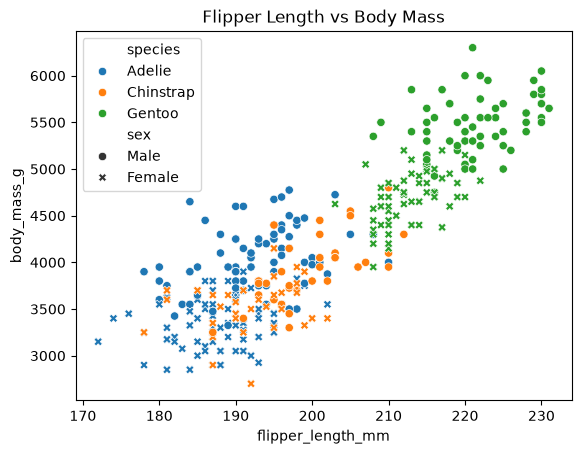

In [9]:
sns.scatterplot(data=penguins,
                x='flipper_length_mm',
                y='body_mass_g',
                hue='species',     # 종을 색으로 구분
                style='sex')       # 성별을 점 모양으로 구분

plt.title('Flipper Length vs Body Mass')
plt.show()

- 하나의 그래프에 네 개의 변수가 표현됨
- 변수를 너무 많이 넣으면 오히려 읽기 어려워지므로 **세 개, 많아야 네 개**가 적당함

#### 여러 변수의 관계를 한 번에 보기
- `pairplot( )` : 숫자형 변수의 모든 쌍에 대해 산점도를 그리고, 대각선에는 각 변수의 분포를 그림
  - 변수가 많을 때 어떤 쌍에 관계가 있는지 빠르게 훑어볼 수 있음
  - 대각선을 기준으로 위아래가 같은 정보를 반복하는 단점이 있음

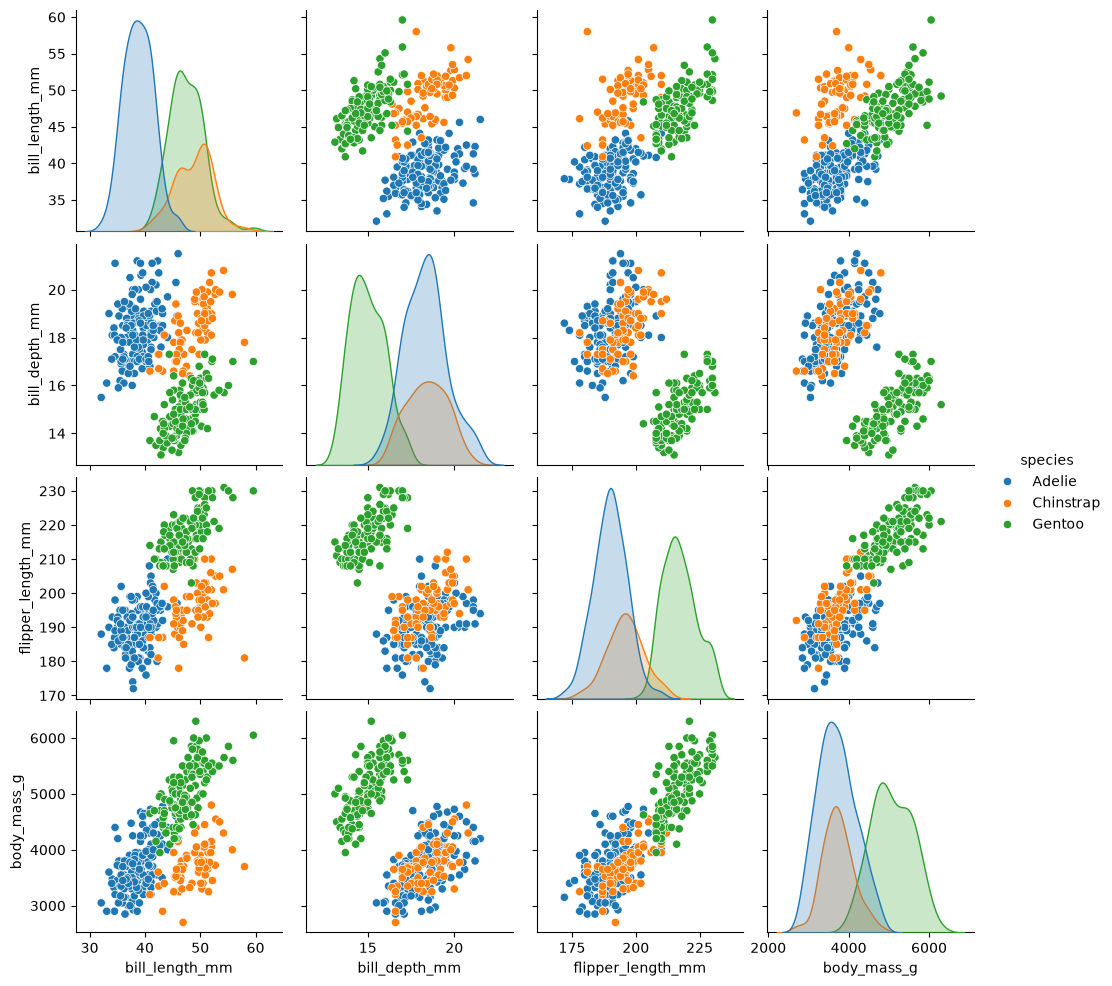

In [11]:
sns.pairplot(data=penguins, hue='species')

plt.show()

- 대부분의 변수 쌍에서 **종별로 점의 무리가 뚜렷하게 나뉨**
- 앞의 심슨의 역설 예제도 이 그래프의 부리 길이 - 부리 깊이 칸에서 확인할 수 있음

### 그래프 나눠 그리기

- 그룹이 여러 개일 때 한 그래프에 색으로 겹쳐 그리면 복잡해질 수 있음
- 그룹마다 **칸을 나누어** 따로 그리면 비교가 쉬워짐
- `FacetGrid` 객체를 이용
  - `col` : 칸을 나눌 기준 변수
  - `col_wrap` : 한 줄에 놓을 칸의 수
  - `map( )` : 각 칸에 그릴 그래프 함수와 변수를 지정

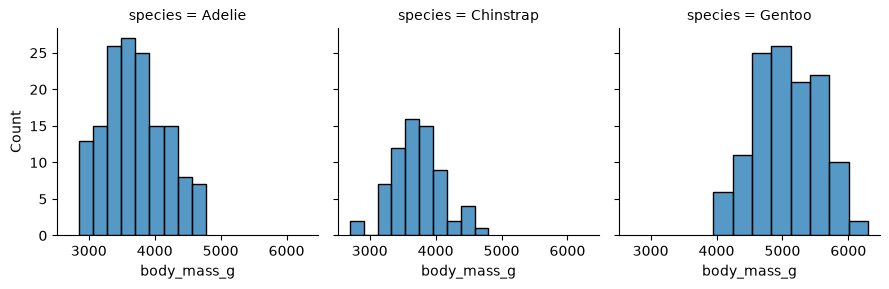

In [12]:
facet = sns.FacetGrid(penguins, col='species')
facet.map(sns.histplot, 'body_mass_g')

plt.show()

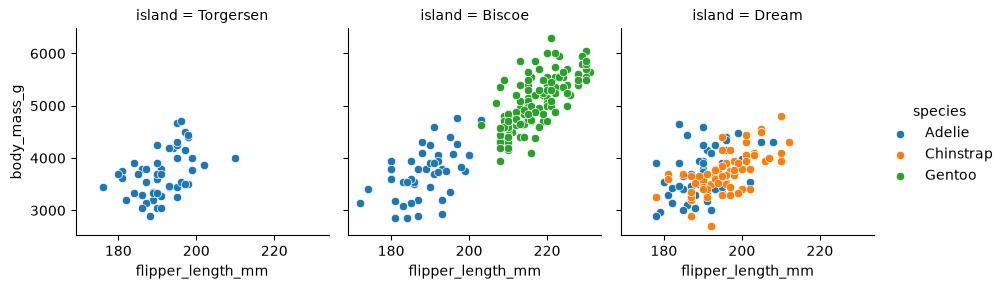

In [13]:
facet = sns.FacetGrid(penguins, col='island', hue='species')
facet.map(sns.scatterplot, 'flipper_length_mm', 'body_mass_g')
facet.add_legend()

plt.show()

- 섬별로 칸을 나누고, 칸 안에서는 종을 색으로 구분함
- Biscoe, Dream 섬에는 두 종이, Torgersen 섬에는 한 종만 있다는 것이 한눈에 보임

### 표 형태 바꾸기 - pivot( )

- 지금까지 다룬 데이터는 **한 행이 관측 하나**인 긴 형태(long format)였음
- heatmap 처럼 **행과 열이 모두 의미를 갖는 표**가 필요한 경우가 있음 (wide format)
- `pivot( )` 은 긴 형태를 넓은 형태로 바꿈
  - `index` : 새 표의 행이 될 변수
  - `columns` : 새 표의 열이 될 변수
  - `values` : 표 안을 채울 값

##### 예제 데이터: 타이타닉
- 객실 등급과 성별에 따른 생존율을 표로 만들어 봄
- 먼저 5주차에 배운 `groupby( )` 로 생존율을 구함

In [14]:
titanic = pd.read_csv('https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv')

rate = titanic.groupby(['Pclass', 'Sex']) \
              .agg(survival=('Survived', 'mean')) \
              .reset_index()

print(rate)

   Pclass     Sex  survival
0       1  female  0.968085
1       1    male  0.368852
2       2  female  0.921053
3       2    male  0.157407
4       3  female  0.500000
5       3    male  0.135447


- 결과는 6행짜리 긴 형태
- 같은 등급의 남녀를 비교하려면 위아래로 떨어진 행을 찾아 봐야 해서 불편함

In [15]:
table = rate.pivot(index='Pclass', columns='Sex', values='survival')

print(table.round(3))

Sex     female   male
Pclass               
1        0.968  0.369
2        0.921  0.157
3        0.500  0.135


- 행은 객실 등급, 열은 성별인 3행 2열의 표가 됨
- 같은 정보지만 **등급 간 비교와 성별 간 비교가 한눈에** 가능해짐
- `pivot( )` 을 쓰기 전에 `reset_index( )` 로 `Pclass`, `Sex` 열을 인덱스가 아니라 데이터프레임의 열로 만든 것에 주의

### heatmap

- `sns.heatmap( )` : 표의 각 칸의 값을 **색의 진하기**로 표현
- 행과 열이 모두 의미를 갖는 표에서 큰 값과 작은 값이 어디에 몰려 있는지 쉽게 드러남
- 주요 매개변수
  - `annot=True` : 각 칸에 값을 함께 표시
  - `fmt` : 표시할 값의 형식 (`'.2f'` 는 소수점 둘째 자리, `'d'` 는 정수)
  - `cmap` : 색상 (`'Blues'`, `'Reds'`, `'viridis'` 등)

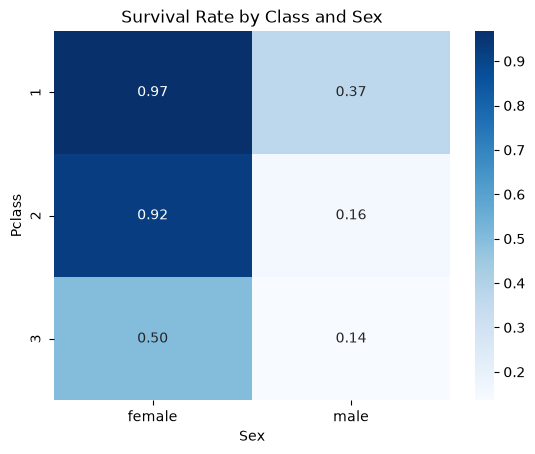

In [16]:
sns.heatmap(table, annot=True, fmt='.2f', cmap='Blues')

plt.title('Survival Rate by Class and Sex')
plt.show()

- 오른쪽 아래(3등석 남성)가 가장 옅고, 왼쪽 위(1등석 여성)가 가장 진함
- 6개의 숫자를 표로 읽는 것보다 패턴이 훨씬 빨리 보임

##### 시간에 따른 패턴 보기 - 항공 승객 데이터
- 1949년부터 1960년까지 연도별, 월별 항공 승객 수
- `year`, `month`, `passengers` 세 열로 된 긴 형태의 데이터

In [17]:
flights = sns.load_dataset('flights')
print(flights.head())
print(flights.shape)

   year month  passengers
0  1949   Jan         112
1  1949   Feb         118
2  1949   Mar         132
3  1949   Apr         129
4  1949   May         121
(144, 3)


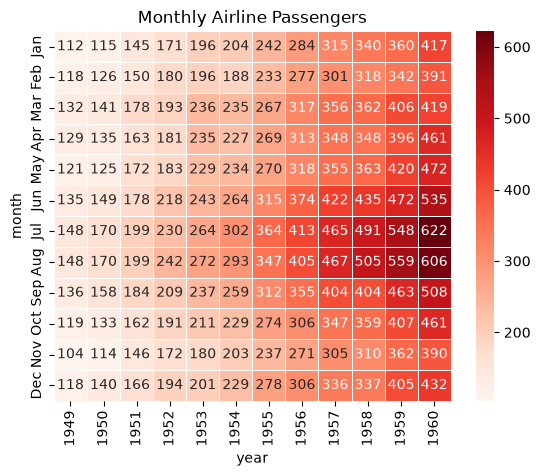

In [18]:
flight_table = flights.pivot(index='month', columns='year', values='passengers')

sns.heatmap(flight_table, annot=True, fmt='d', cmap='Reds', linewidths=0.5)

plt.title('Monthly Airline Passengers')
plt.show()

- **왼쪽에서 오른쪽으로** 갈수록 진해짐 : 해가 갈수록 승객이 늘어나는 추세
- **7월, 8월 줄**이 매년 가장 진함 : 여름철에 승객이 많은 계절 패턴
- 144개의 숫자에서 두 가지 패턴을 동시에 읽을 수 있음

### 연습 문제

- 타이타닉 승객 데이터를 이용함 (위에서 만든 변수 `titanic` 사용)

##### 1. 나이(`Age`)와 요금(`Fare`)의 관계를 산점도로 그리시오.
- 객실 등급(`Pclass`)을 색으로 구분할 것
- 나이와 요금 사이에 뚜렷한 관계가 있는지, 아니면 등급에 따라 무리가 나뉘는지 그래프를 보고 답할 것

##### 2. 생존 여부(`Survived`)에 따라 칸을 나누어 나이의 히스토그램을 그리시오.
- `FacetGrid` 를 이용할 것

##### 3. 객실 등급과 탑승 항구(`Embarked`)에 따른 생존율을 heatmap 으로 그리시오.
- 행은 객실 등급, 열은 탑승 항구
- 각 칸에 생존율을 소수점 둘째 자리까지 표시할 것

> **힌트**
> - 위에서 다룬 객실 등급 × 성별 생존율 heatmap 예제와 같은 순서로 풀 수 있음
>   1. `groupby( )` 로 객실 등급과 탑승 항구별 생존율을 구함 (`Survived` 의 평균)
>   2. `reset_index( )` 로 객실 등급과 탑승 항구를 인덱스가 아닌 열로 만듦
>   3. `pivot( )` 으로 행은 객실 등급, 열은 탑승 항구인 표로 바꿈
>   4. `heatmap( )` 으로 그리되, 값 표시와 소수점 자릿수를 지정하는 매개변수를 사용